In [1]:
import pandas as pd
from rdkit import Chem

In [2]:
df = pd.read_csv("../data/tox21_nr_ahr_clean.csv")

print(df.shape)
print(df.head())

(6534, 2)
                                 smiles  NR-AhR
0          CCOc1ccc2nc(S(N)(=O)=O)sc2c1     1.0
1             CCN1C(=O)NC(c2ccccc2)C1=O     0.0
2       CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C     0.0
3  CC(C)(C)OOC(C)(C)CCC(C)(C)OOC(C)(C)C     0.0
4                   O=S(=O)(Cl)c1ccccc1     0.0


In [3]:
df['mol'] = df['smiles'].apply(Chem.MolFromSmiles)

print(df['mol'].isna().sum())

0


[23:10:29] WARNING: not removing hydrogen atom without neighbors


In [4]:
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors

df['MolWt'] = df['mol'].apply(Descriptors.MolWt)
df['MolLogP'] = df['mol'].apply(Descriptors.MolLogP)
df['TPSA'] = df['mol'].apply(Descriptors.TPSA)

df['NumHDonors'] = df['mol'].apply(Lipinski.NumHDonors)
df['NumHAcceptors'] = df['mol'].apply(Lipinski.NumHAcceptors)
df['NumRotatableBonds'] = df['mol'].apply(Lipinski.NumRotatableBonds)

df['RingCount'] = df['mol'].apply(Lipinski.RingCount)
df['NumAromaticRings'] = df['mol'].apply(Lipinski.NumAromaticRings)

df['HeavyAtomCount'] = df['mol'].apply(Lipinski.HeavyAtomCount)
df['FractionCSP3'] = df['mol'].apply(rdMolDescriptors.CalcFractionCSP3)

In [5]:
print(df.shape)

(6534, 13)


In [6]:
print(df.columns)

print(df.columns)

print(df.isnull().sum())

df.describe()

Index(['smiles', 'NR-AhR', 'mol', 'MolWt', 'MolLogP', 'TPSA', 'NumHDonors',
       'NumHAcceptors', 'NumRotatableBonds', 'RingCount', 'NumAromaticRings',
       'HeavyAtomCount', 'FractionCSP3'],
      dtype='str')
Index(['smiles', 'NR-AhR', 'mol', 'MolWt', 'MolLogP', 'TPSA', 'NumHDonors',
       'NumHAcceptors', 'NumRotatableBonds', 'RingCount', 'NumAromaticRings',
       'HeavyAtomCount', 'FractionCSP3'],
      dtype='str')
smiles               0
NR-AhR               0
mol                  0
MolWt                0
MolLogP              0
TPSA                 0
NumHDonors           0
NumHAcceptors        0
NumRotatableBonds    0
RingCount            0
NumAromaticRings     0
HeavyAtomCount       0
FractionCSP3         0
dtype: int64


,NR-AhR,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,RingCount,NumAromaticRings,HeavyAtomCount,FractionCSP3
count,6534.000000,6534.000000,6534.000000,6534.000000,6534.000000,6534.000000,6534.000000,6534.00000,6534.000000,6534.000000,6534.000000
mean,0.116315,268.938037,2.325807,57.982960,1.191001,3.376186,4.240741,1.68794,1.039027,18.067493,0.470084
std,0.320626,164.563574,2.296053,58.190565,1.926382,3.114463,4.444951,1.65771,1.078224,11.304757,0.331212
min,0.000000,9.012000,-17.406400,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000
25%,0.000000,159.214750,1.103825,26.020000,0.000000,2.000000,1.000000,1.00000,0.000000,11.000000,0.181818
50%,0.000000,230.559000,2.322000,44.760000,1.000000,3.000000,3.000000,1.00000,1.000000,16.000000,0.436141
75%,0.000000,332.480250,3.609750,74.600000,2.000000,4.000000,6.000000,3.00000,2.000000,23.000000,0.750000
max,1.000000,1877.664000,22.611800,777.980000,30.000000,46.000000,47.000000,30.00000,10.000000,132.000000,1.000000


In [7]:
feature_cols = [
    'MolWt',
    'MolLogP',
    'TPSA',
    'NumHDonors',
    'NumHAcceptors',
    'NumRotatableBonds',
    'RingCount',
    'NumAromaticRings',
    'HeavyAtomCount',
    'FractionCSP3'
]

X = df[feature_cols]
y = df['NR-AhR']

print(X.shape)
print(y.shape)

(6534, 10)
(6534,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
print("Training set:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTest set:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

Training set:
NR-AhR
0.0    4619
1.0     608
Name: count, dtype: int64
NR-AhR
0.0    0.883681
1.0    0.116319
Name: proportion, dtype: float64

Test set:
NR-AhR
0.0    1155
1.0     152
Name: count, dtype: int64
NR-AhR
0.0    0.883703
1.0    0.116297
Name: proportion, dtype: float64


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [11]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_rf = rf_model.predict(X_test)

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC:", average_precision_score(y_test, y_prob_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))

ROC-AUC: 0.8653280929596718
PR-AUC: 0.5009662718995881
Precision: 0.5945945945945946
Recall: 0.2894736842105263
F1: 0.3893805309734513


In [12]:
%pip install xgboost
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [13]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb_model.predict(X_test)

print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))
print("PR-AUC:", average_precision_score(y_test, y_prob_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))

ROC-AUC: 0.8717874231032126
PR-AUC: 0.4969357993702153
Precision: 0.6086956521739131
Recall: 0.3684210526315789
F1: 0.45901639344262296


In [14]:
import numpy as np

np.set_printoptions(threshold=np.inf)

print(y_prob_xgb)

[2.27482077e-02 6.20650277e-02 3.90007086e-02 9.70334839e-03
 1.47042554e-02 1.53109446e-01 1.62317187e-01 2.13726028e-03
 2.32049939e-03 1.89936825e-03 4.21542936e-04 1.08802542e-02
 3.51067632e-02 2.20070127e-02 8.15195218e-02 1.93459988e-01
 2.61778235e-01 2.63552852e-02 2.02125609e-01 7.79448897e-02
 2.95937508e-01 8.74086376e-03 2.25805142e-03 9.19877738e-03
 5.17392576e-01 5.15230894e-01 2.68229753e-01 9.77738295e-03
 5.29110208e-02 1.19907944e-03 1.18647488e-02 3.14547867e-02
 2.08811551e-01 6.90707564e-02 6.96866661e-02 4.81847256e-01
 8.60283077e-02 1.09229144e-02 5.62386448e-03 2.03129023e-01
 1.49110317e-01 1.81400970e-01 1.00329891e-01 4.01817635e-03
 6.35884749e-03 2.40475917e-03 1.99703909e-02 8.07700217e-01
 3.57201789e-04 5.35248080e-03 5.63569227e-03 1.12697659e-02
 2.01179273e-02 7.05720901e-01 5.71341021e-04 3.59895416e-02
 1.25166342e-01 1.19712006e-03 2.71547493e-03 5.68344109e-02
 3.89044930e-04 5.05010545e-01 1.39712831e-02 8.66232347e-03
 1.13392668e-02 5.532189

In [15]:
print(y_test.to_numpy())

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0.
 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1.

In [16]:
import numpy as np

np.set_printoptions(threshold=np.inf)

print("y_test:")
print(y_test.to_numpy())

print("y_prob_xgb:")
print(y_prob_xgb)

y_test:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.
 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0.
 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 

In [17]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

scale_pos_weight = neg / pos

print("Training negatives:", neg)
print("Training positives:", pos)
print("scale_pos_weight:", scale_pos_weight)

Training negatives: 4619
Training positives: 608
scale_pos_weight: 7.597039473684211


In [18]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [19]:
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    print(
        f"Fold {fold}: "
        f"train positives = {y_fold_train.sum()}, "
        f"validation positives = {y_fold_val.sum()}"
    )

Fold 1: train positives = 486.0, validation positives = 122.0
Fold 2: train positives = 486.0, validation positives = 122.0
Fold 3: train positives = 487.0, validation positives = 121.0
Fold 4: train positives = 487.0, validation positives = 121.0
Fold 5: train positives = 486.0, validation positives = 122.0


In [20]:
from sklearn.model_selection import cross_validate

xgb_unweighted = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=1
)

xgb_weighted = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=7.597
)

In [21]:
from sklearn.model_selection import cross_validate

scoring = {
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

In [22]:
cv_unweighted = cross_validate(
    xgb_unweighted,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [23]:
print("Unweighted XGBoost")
print("Mean ROC-AUC:", cv_unweighted['test_roc_auc'].mean())
print("Mean PR-AUC:", cv_unweighted['test_pr_auc'].mean())

Unweighted XGBoost
Mean ROC-AUC: 0.8552697694204676
Mean PR-AUC: 0.5301883170423511


In [24]:
cv_weighted = cross_validate(
    xgb_weighted,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [25]:
print("Weighted XGBoost")
print("Mean ROC-AUC:", cv_weighted['test_roc_auc'].mean())
print("Mean PR-AUC:", cv_weighted['test_pr_auc'].mean())

Weighted XGBoost
Mean ROC-AUC: 0.8562935735910552
Mean PR-AUC: 0.530191751825974


In [26]:
print("Weighted XGBoost ROC-AUC:")
print(cv_weighted['test_roc_auc'])

print("\nWeighted XGBoost PR-AUC:")
print(cv_weighted['test_pr_auc'])

Weighted XGBoost ROC-AUC:
[0.84750461 0.88199028 0.86108279 0.85147222 0.83941797]

Weighted XGBoost PR-AUC:
[0.52191479 0.55583764 0.53219169 0.53927608 0.50173856]


In [27]:
print("Unweighted XGBoost ROC-AUC:")
print(cv_unweighted['test_roc_auc'])

print("\nUnweighted XGBoost PR-AUC:")
print(cv_unweighted['test_pr_auc'])

Unweighted XGBoost ROC-AUC:
[0.84534898 0.88243382 0.8611454  0.85185682 0.83556382]

Unweighted XGBoost PR-AUC:
[0.52711695 0.55276132 0.55154744 0.51333673 0.50617916]


In [28]:
results = {
    'Unweighted XGBoost': {
        'ROC-AUC': cv_unweighted['test_roc_auc'].mean(),
        'PR-AUC': cv_unweighted['test_pr_auc'].mean()
    },
    'Weighted XGBoost': {
        'ROC-AUC': cv_weighted['test_roc_auc'].mean(),
        'PR-AUC': cv_weighted['test_pr_auc'].mean()
    }
}

import pandas as pd

results_df = pd.DataFrame(results).T
print(results_df)

                     ROC-AUC    PR-AUC
Unweighted XGBoost  0.855270  0.530188
Weighted XGBoost    0.856294  0.530192


In [29]:
from sklearn.model_selection import GridSearchCV

xgb_tuning = XGBClassifier(
    scale_pos_weight=7.597,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [200, 400],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_child_weight': [1, 3],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb_tuning,
    param_grid=param_grid,
    scoring='average_precision',
    cv=skf,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5, ...], 'min_child_weight': [1, 3], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the 

In [30]:
print("Best max_depth:", grid_search.best_params_)
print("Best CV PR-AUC:", grid_search.best_score_)

Best max_depth: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 200, 'subsample': 0.8}
Best CV PR-AUC: 0.5357441939256272


In [31]:
results = pd.DataFrame(grid_search.cv_results_)

top_results = results.sort_values(
    'mean_test_score',
    ascending=False
).head(10)

print(
    top_results[
        [
            'param_n_estimators',
            'param_learning_rate',
            'param_max_depth',
            'param_min_child_weight',
            'param_subsample',
            'param_colsample_bytree',
            'mean_test_score',
            'std_test_score'
        ]
    ].to_string(index=False)
)

 param_n_estimators  param_learning_rate  param_max_depth  param_min_child_weight  param_subsample  param_colsample_bytree  mean_test_score  std_test_score
                200                 0.05                7                       1              0.8                     1.0         0.535744        0.020553
                200                 0.05                7                       3              0.8                     1.0         0.534699        0.016899
                200                 0.05                5                       1              0.8                     0.8         0.530325        0.018607
                200                 0.05                7                       1              1.0                     1.0         0.530324        0.024393
                200                 0.05                7                       3              1.0                     0.8         0.528919        0.017405
                200                 0.05                7       

In [32]:
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier

scale_weights = [4, 6, 7.6, 10, 12]

scale_results = []

for weight in scale_weights:

    model = XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=7,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=1.0,
        scale_pos_weight=weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )

    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=skf,
        scoring={
            'roc_auc': 'roc_auc',
            'pr_auc': 'average_precision'
        },
        n_jobs=-1
    )

    scale_results.append({
        'scale_pos_weight': weight,
        'mean_roc_auc': cv_result['test_roc_auc'].mean(),
        'mean_pr_auc': cv_result['test_pr_auc'].mean()
    })

scale_results

[{'scale_pos_weight': 4,
  'mean_roc_auc': np.float64(0.8585731628942834),
  'mean_pr_auc': np.float64(0.536527119041479)},
 {'scale_pos_weight': 6,
  'mean_roc_auc': np.float64(0.8579955716940237),
  'mean_pr_auc': np.float64(0.5289466471572567)},
 {'scale_pos_weight': 7.6,
  'mean_roc_auc': np.float64(0.8599333136302105),
  'mean_pr_auc': np.float64(0.539946767254339)},
 {'scale_pos_weight': 10,
  'mean_roc_auc': np.float64(0.8591657629574027),
  'mean_pr_auc': np.float64(0.5275899438721985)},
 {'scale_pos_weight': 12,
  'mean_roc_auc': np.float64(0.8571677586082911),
  'mean_pr_auc': np.float64(0.5190464649270125)}]

In [33]:
import pandas as pd

scale_results_df = pd.DataFrame(scale_results)

scale_results_df.sort_values(
    'mean_pr_auc',
    ascending=False
)

,scale_pos_weight,mean_roc_auc,mean_pr_auc
2,7.6,0.859933,0.539947
0,4.0,0.858573,0.536527
1,6.0,0.857996,0.528947
3,10.0,0.859166,0.527590
4,12.0,0.857168,0.519046


In [34]:
best_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=7,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=7.597,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

In [35]:
tuned_cv = cross_validate(
    best_xgb,
    X_train,
    y_train,
    cv=skf,
    scoring={
        'roc_auc': 'roc_auc',
        'pr_auc': 'average_precision'
    },
    n_jobs=-1
)

Trying to fix training data overfitting

In [36]:
regularized_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=7.6,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

cv_regularized = cross_validate(
    regularized_xgb,
    X_train,
    y_train,
    cv=skf,
    scoring={
        'roc_auc': 'roc_auc',
        'pr_auc': 'average_precision'
    },
    n_jobs=-1
)

print("Regularized Mean ROC-AUC:",
      cv_regularized['test_roc_auc'].mean())

print("Regularized Mean PR-AUC:",
      cv_regularized['test_pr_auc'].mean())

Regularized Mean ROC-AUC: 0.8565358567014656
Regularized Mean PR-AUC: 0.504870812104966


In [37]:
print("ROC-AUC folds:",
      cv_regularized['test_roc_auc'])

print("PR-AUC folds:",
      cv_regularized['test_pr_auc'])

ROC-AUC folds: [0.84220868 0.88676283 0.86317574 0.84482666 0.84570538]
PR-AUC folds: [0.50124679 0.53006769 0.52308143 0.47588637 0.49407178]


In [38]:
print("Tuned XGBoost")
print("Mean ROC-AUC:", tuned_cv['test_roc_auc'].mean())
print("Mean PR-AUC:", tuned_cv['test_pr_auc'].mean())

print("\nROC-AUC by fold:")
print(tuned_cv['test_roc_auc'])

print("\nPR-AUC by fold:")
print(tuned_cv['test_pr_auc'])

Tuned XGBoost
Mean ROC-AUC: 0.8593929695629006
Mean PR-AUC: 0.5357441939256272

ROC-AUC by fold:
[0.8514433  0.88372898 0.87096616 0.8549873  0.83583912]

PR-AUC by fold:
[0.52037273 0.55023312 0.56668599 0.53204244 0.50938667]


In [39]:
best_xgb.fit(X_train, y_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,1.0
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBR

In [40]:
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = best_xgb.predict(X_test)

In [41]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Predictions on training data
y_prob_train = best_xgb.predict_proba(X_train)[:, 1]

# Training metrics
train_roc_auc = roc_auc_score(y_train, y_prob_train)
train_pr_auc = average_precision_score(y_train, y_prob_train)

print("Training ROC-AUC:", train_roc_auc)
print("Training PR-AUC :", train_pr_auc)

Training ROC-AUC: 0.9966888053919166
Training PR-AUC : 0.9714752800065674


In [42]:
roc_auc = roc_auc_score(y_test, y_prob_xgb)
pr_auc = average_precision_score(y_test, y_prob_xgb)
precision = precision_score(y_test, y_pred_xgb)
recall = recall_score(y_test, y_pred_xgb)
f1 = f1_score(y_test, y_pred_xgb)

print("Final Test Results")
print("ROC-AUC :", roc_auc)
print("PR-AUC  :", pr_auc)
print("Precision:", precision)
print("Recall   :", recall)
print("F1       :", f1)

Final Test Results
ROC-AUC : 0.8708589655958078
PR-AUC  : 0.4970149502912161
Precision: 0.43317972350230416
Recall   : 0.618421052631579
F1       : 0.5094850948509485


In [43]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_xgb)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1032  123]
 [  58   94]]


SHAP ANALYSIS 

In [44]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import shap

In [46]:
explainer = shap.TreeExplainer(best_xgb)

In [47]:
shap_values = explainer(X_test)
shap_values.shape

(1307, 10)

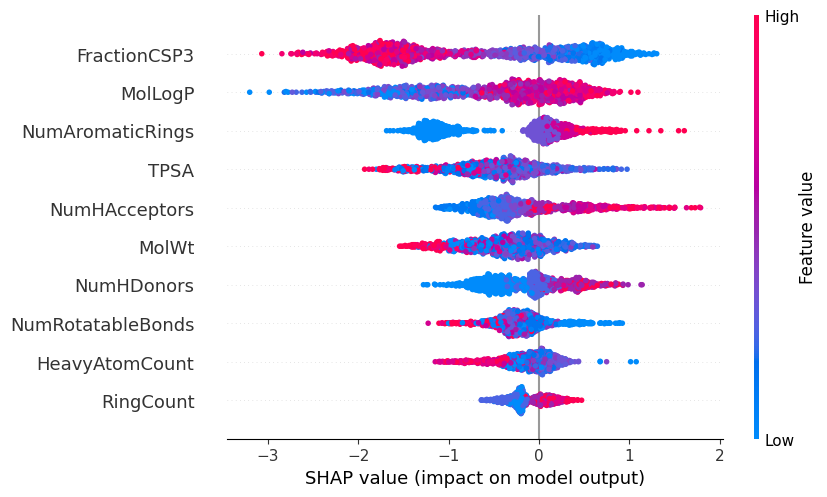

In [48]:
shap.plots.beeswarm(shap_values, max_display=10)

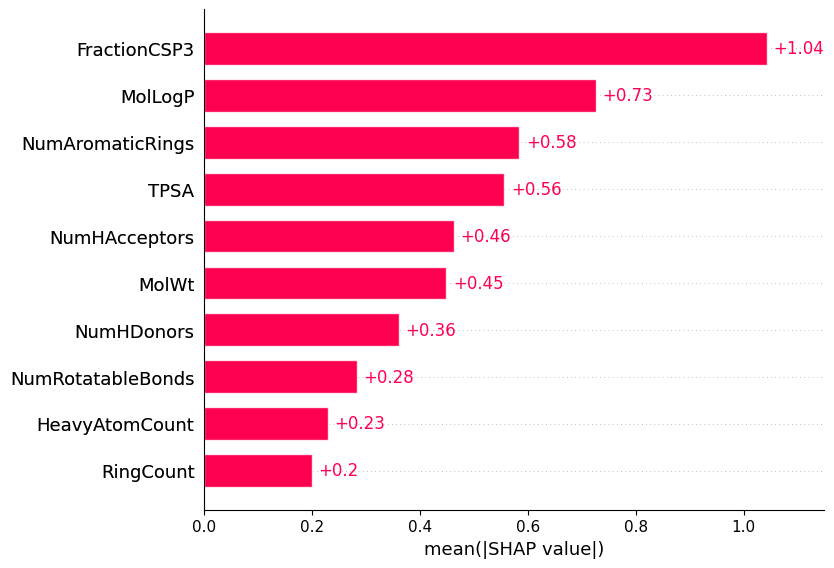

In [49]:
shap.plots.bar(shap_values, max_display=10)

In [50]:
import sys
import numpy
import scipy
import rdkit
import xgboost
import shap
import sklearn
import Bio

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("RDKit:", rdkit.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)
print("scikit-learn:", sklearn.__version__)
print("Biopython:", Bio.__version__)


Python: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.4.4
SciPy: 1.17.1
RDKit: 2026.03.6
XGBoost: 3.4.1
SHAP: 0.52.0
scikit-learn: 1.8.0
Biopython: 1.88


In [52]:
print(y_prob_xgb.shape)
print(y_test.shape)
print(roc_auc_score(y_test, y_prob_xgb))
print(average_precision_score(y_test, y_prob_xgb))

(1307,)
(1307,)
0.8708589655958078
0.4970149502912161


In [55]:
np.random.seed(42)

n_bootstrap = 2000

bootstrap_roc = []
bootstrap_pr = []

for _ in range(n_bootstrap):
    indices = np.random.choice(len(y_test), size=len(y_test), replace=True)

    y_boot = y_test.iloc[indices]
    prob_boot = y_prob_xgb[indices]

    if len(np.unique(y_boot)) < 2:
        continue

    bootstrap_roc.append(
        roc_auc_score(y_boot, prob_boot)
    )

    bootstrap_pr.append(
        average_precision_score(y_boot, prob_boot)
    )

roc_ci_2A = np.percentile(bootstrap_roc, [2.5, 97.5])
pr_ci_2A = np.percentile(bootstrap_pr, [2.5, 97.5])



In [56]:
print("Model 2A Test ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))
print("Model 2A ROC-AUC 95% CI:", roc_ci_2A)

print("Model 2A Test PR-AUC:", average_precision_score(y_test, y_prob_xgb))
print("Model 2A PR-AUC 95% CI:", pr_ci_2A)

Model 2A Test ROC-AUC: 0.8708589655958078
Model 2A ROC-AUC 95% CI: [0.84218727 0.89644231]
Model 2A Test PR-AUC: 0.4970149502912161
Model 2A PR-AUC 95% CI: [0.41791246 0.58774501]
